# Panorama Viewer

This notebook:
1. Takes a lat/lng coordinate
2. Fetches the nearest Google Street View panorama + metadata
3. Displays a map with both the input location and panorama location
4. Displays the panorama with perspective views at 0°, 90°, 180°, 270°
5. Shows a map with the bearing angle from the panorama to the input location
6. Displays the perspective view at that calculated heading using `_extract_perspective_view`


In [83]:
!!uv pip install folium
import math
import asyncio
import aiohttp
import numpy as np
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from streetlevel import streetview as streetlevel_streetview
import folium
from IPython.display import display, HTML

# Import the perspective view extraction from our streetview module
import sys
sys.path.insert(0, '.')
from bench_finder.core.streetview import StreetViewClient


In [84]:
# =============================================================================
# INPUT: Set your latitude and longitude here
# =============================================================================
INPUT_LAT = 52.36560281265296
INPUT_LNG =  4.873465022986906

# Search radius for finding panorama (meters)
SEARCH_RADIUS = 50

print(f"📍 Input location: ({INPUT_LAT}, {INPUT_LNG})")


📍 Input location: (52.36560281265296, 4.873465022986906)


In [85]:
def calculate_bearing(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """
    Calculate the bearing (heading) from point 1 to point 2 in degrees.
    
    Args:
        lat1: Latitude of starting point (panorama location)
        lon1: Longitude of starting point (panorama location)
        lat2: Latitude of destination point (input location)
        lon2: Longitude of destination point (input location)
    
    Returns:
        Bearing in degrees (0-360, where 0 is North)
    """
    lat1_rad = math.radians(lat1)
    lat2_rad = math.radians(lat2)
    delta_lon = math.radians(lon2 - lon1)
    
    y = math.sin(delta_lon) * math.cos(lat2_rad)
    x = math.cos(lat1_rad) * math.sin(lat2_rad) - math.sin(lat1_rad) * math.cos(lat2_rad) * math.cos(delta_lon)
    
    bearing = math.atan2(y, x)
    bearing_degrees = math.degrees(bearing)
    
    # Normalize to 0-360
    return (bearing_degrees + 360) % 360


def haversine_distance(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """Calculate distance between two points in meters."""
    R = 6371000  # Earth radius in meters
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    delta_phi = math.radians(lat2 - lat1)
    delta_lambda = math.radians(lon2 - lon1)
    
    a = math.sin(delta_phi/2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(delta_lambda/2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1-a))
    
    return R * c


In [86]:
# =============================================================================
# Fetch the panorama from Google Street View using streetlevel
# =============================================================================

async def fetch_panorama(lat: float, lng: float, radius: int = 50):
    """Fetch panorama and metadata from Google Street View."""
    async with aiohttp.ClientSession() as session:
        # Find panorama near the location
        pano = await streetlevel_streetview.find_panorama_async(
            lat=lat, lon=lng, radius=100, session=session
        )
        
        if not pano:
            print(f"❌ No panorama found within {radius}m of ({lat}, {lng})")
            return None, None, None

        print(pano)
        print("heading:", pano.heading)
        
        # Get panorama metadata
        pano_lat = pano.lat if hasattr(pano, 'lat') else lat
        pano_lng = pano.lon if hasattr(pano, 'lon') else lng
        pano_id = pano.id if hasattr(pano, 'id') else None
        pano_date = str(pano.date) if hasattr(pano, 'date') else None
        
        metadata = {
            'pano_id': pano_id,
            'lat': pano_lat,
            'lng': pano_lng,
            'date': pano_date,
            'heading': pano.heading if hasattr(pano, 'heading') else None,
        }
        
        print(f"✅ Found panorama!")
        print(f"   📍 Panorama location: ({pano_lat:.6f}, {pano_lng:.6f})")
        print(f"   🆔 Pano ID: {pano_id}")
        print(f"   📅 Date: {pano_date}")
        
        # Download the equirectangular panorama
        print("   ⬇️ Downloading panorama tiles...")
        equirectangular = await streetlevel_streetview.get_panorama_async(
            pano, zoom=3, session=session
        )
        
        if equirectangular:
            print(f"   ✅ Downloaded! Size: {equirectangular.size}")
        else:
            print("   ❌ Failed to download panorama")
        
        return pano, equirectangular, metadata

# Fetch the panorama
pano, equirectangular, metadata = await fetch_panorama(INPUT_LAT, INPUT_LNG, 500)


X0E7lSfvQ683dOwoxqM8jQ (52.36562, 4.87338)
heading: 5.853612097027624
✅ Found panorama!
   📍 Panorama location: (52.365616, 4.873384)
   🆔 Pano ID: X0E7lSfvQ683dOwoxqM8jQ
   📅 Date: 2024-09
   ⬇️ Downloading panorama tiles...
   ✅ Downloaded! Size: (4096, 2048)


In [87]:
# =============================================================================
# Display map with input location and panorama location
# =============================================================================

if metadata:
    pano_lat = metadata['lat']
    pano_lng = metadata['lng']
    
    # Calculate center point
    center_lat = (INPUT_LAT + pano_lat) / 2
    center_lng = (INPUT_LNG + pano_lng) / 2
    
    # Calculate distance
    distance = haversine_distance(INPUT_LAT, INPUT_LNG, pano_lat, pano_lng)
    
    print(f"📏 Distance between input and panorama: {distance:.1f} meters")
    
    # Create map
    m = folium.Map(location=[center_lat, center_lng], zoom_start=18)
    
    # Add input location marker (red)
    folium.Marker(
        [INPUT_LAT, INPUT_LNG],
        popup=f'Input Location<br>({INPUT_LAT:.6f}, {INPUT_LNG:.6f})',
        icon=folium.Icon(color='red', icon='crosshairs', prefix='fa'),
        tooltip='Input Location'
    ).add_to(m)
    
    # Add panorama location marker (blue)
    folium.Marker(
        [pano_lat, pano_lng],
        popup=f'Panorama Location<br>({pano_lat:.6f}, {pano_lng:.6f})<br>ID: {metadata["pano_id"]}',
        icon=folium.Icon(color='blue', icon='camera', prefix='fa'),
        tooltip='Panorama Location'
    ).add_to(m)
    
    # Add line between the two points
    folium.PolyLine(
        [[INPUT_LAT, INPUT_LNG], [pano_lat, pano_lng]],
        color='purple',
        weight=3,
        opacity=0.7,
        dash_array='10'
    ).add_to(m)
    
    display(HTML("<h3>🗺️ Map: Input Location (red) vs Panorama Location (blue)</h3>"))
    display(m)
else:
    print("No panorama found to display on map.")


📏 Distance between input and panorama: 5.7 meters


In [ ]:
# =============================================================================
# Extract perspective view function (from streetview.py)
# =============================================================================

def extract_perspective_view(
    equirectangular: PILImage.Image,
    heading: float,
    fov: int = 90,
    size: tuple[int, int] = (800, 800),
    panorama_heading_rad: float | None = None,
) -> PILImage.Image:
    """
    Extract a perspective view from an equirectangular panorama.
    
    Args:
        equirectangular: The full equirectangular panorama image
        heading: Compass heading in degrees (0-360, where 0 is North) - geographic heading
        fov: Field of view in degrees
        size: Output image size (width, height)
        panorama_heading_rad: The heading of the panorama's center in radians.
            This is the direction the panorama is "facing" (where 0° is North).
            If provided, the heading will be adjusted to account for this offset.
    
    Returns:
        Perspective view image at the specified heading and FOV
    """
    try:
        from equilib import equi2pers
    except ImportError:
        try:
            from pyequilib import equi2pers
        except ImportError:
            print("⚠️ equilib/pyequilib not available, using manual projection")
            return extract_perspective_view_manual(equirectangular, heading, fov, size, panorama_heading_rad)
    
    width, height = size
    
    # Convert PIL Image to numpy array
    equi_array = np.asarray(equirectangular)
    
    # Ensure channel-first format (C, H, W) for equi2pers
    if len(equi_array.shape) == 3 and (equi_array.shape[2] == 3 or equi_array.shape[2] == 4):
        equi_array = np.transpose(equi_array, (2, 0, 1))
    
    # Remove alpha channel if present
    if equi_array.shape[0] == 4:
        equi_array = equi_array[:3, :, :]
    
    # Convert target heading to degrees
    yaw_deg = float(heading)
    
    # Adjust for panorama's heading offset
    # The panorama's center (yaw=0 in panorama coords) points at panorama_heading_rad direction
    # equi2pers uses a convention where 0° yaw = East (90° geographic), not North
    # So we need to: 
    # 1. Convert geographic heading to panorama coords: panorama_yaw = geographic_heading - panorama_heading
    # 2. Account for the 90° offset: panorama_yaw = panorama_yaw + 90 (add instead of subtract)
    # Combined: panorama_yaw = geographic_heading - panorama_heading + 90
    if panorama_heading_rad is not None:
        panorama_heading_deg = np.degrees(panorama_heading_rad)
        # Account for both panorama heading offset AND the 90° coordinate system offset
        # Adding 90° instead of subtracting to correct the clockwise offset
        yaw_deg = (yaw_deg - panorama_heading_deg + 90) % 360
    
    # Extract perspective view
    rots_dict = {
        'roll': 0.0,
        'pitch': 0.0,
        'yaw': np.deg2rad(yaw_deg),
    }
    
    pers_img = equi2pers(
        equi=equi_array,
        rots=rots_dict,
        height=height,
        width=width,
        mode='bilinear',
        clip_output=False,
        fov_x=fov,
    )
    
    # Convert back to H, W, C format for PIL
    if len(pers_img.shape) == 3 and pers_img.shape[0] == 3:
        pers_img = np.transpose(pers_img, (1, 2, 0))
    
    pers_img = np.clip(pers_img, 0, 255).astype(np.uint8)
    
    return PILImage.fromarray(pers_img)


def extract_perspective_view_manual(
    equirectangular: PILImage.Image,
    heading: float,
    fov: int,
    size: tuple[int, int],
    panorama_heading_rad: float | None = None,
) -> PILImage.Image:
    """Fallback manual extraction method."""
    width, height = size
    pano_width, pano_height = equirectangular.size
    
    fov_rad = np.radians(fov)
    
    # Adjust heading for panorama's heading offset and coordinate system
    adjusted_heading = heading
    if panorama_heading_rad is not None:
        panorama_heading_deg = np.degrees(panorama_heading_rad)
        # Account for both panorama heading offset AND the 90° coordinate system offset
        # Adding 90° instead of subtracting to correct the clockwise offset
        adjusted_heading = (heading - panorama_heading_deg + 90) % 360
    
    heading_rad = np.radians(adjusted_heading)
    
    f = 0.5 * width / np.tan(0.5 * fov_rad)
    
    x, y = np.meshgrid(np.arange(width), np.arange(height))
    
    x_c = x - width / 2
    y_c = y - height / 2
    z_c = np.full_like(x_c, f)
    
    norm = np.sqrt(x_c**2 + y_c**2 + z_c**2)
    x_n = x_c / norm
    y_n = y_c / norm
    z_n = z_c / norm
    
    phi = np.arctan2(x_n, z_n)
    theta = np.arcsin(y_n)
    
    phi_world = phi + heading_rad
    phi_world = (phi_world + np.pi) % (2 * np.pi) - np.pi
    
    u = (phi_world + np.pi) / (2 * np.pi)
    v = (theta + np.pi / 2) / np.pi
    
    src_x = u * pano_width
    src_y = v * pano_height
    
    src_x = np.mod(src_x, pano_width)
    src_y = np.clip(src_y, 0, pano_height - 1)
    
    src_x_int = src_x.astype(int)
    src_y_int = src_y.astype(int)
    
    pano_array = np.array(equirectangular)
    output_array = pano_array[src_y_int, src_x_int]
    
    return PILImage.fromarray(output_array)


📐 Panorama heading: 335.4° (panorama 0° = 335.4° geographic)


/var/folders/tl/40rt5yw54v150s3k8shhw5y00000gn/T/ipykernel_17596/1210720421.py:57: UserWarning: Glyph 129517 (\N{COMPASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


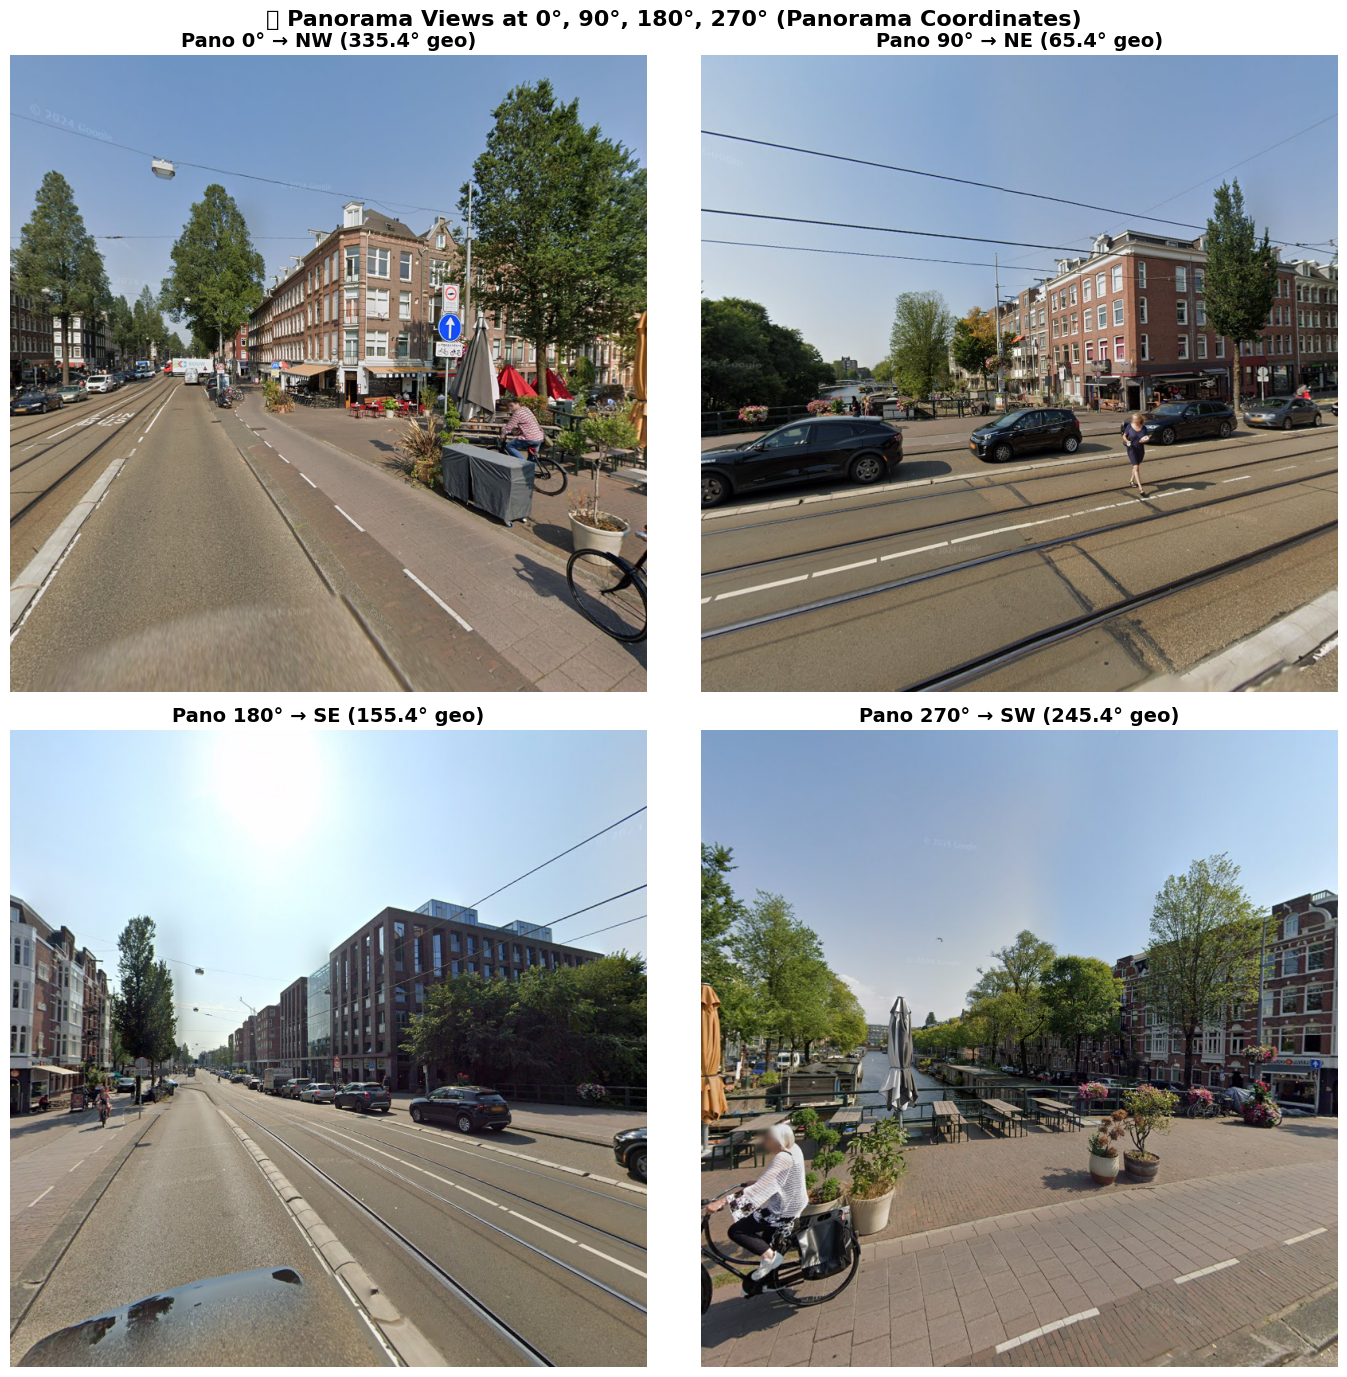

In [ ]:
# =============================================================================
# Display panorama with overlays at 0°, 90°, 180°, 270° (panorama coordinates)
# =============================================================================

if equirectangular:
    pano_headings = [0, 90, 180, 270]  # Panorama coordinate headings (geographic)
    
    # Get panorama heading in radians (direction the pano center is facing)
    pano_heading_rad = metadata.get('heading') if metadata else None
    
    # Calculate geographic headings for each panorama direction
    heading_labels = []
    if pano_heading_rad is not None:
        pano_heading_deg = np.degrees(pano_heading_rad)
        print(f"📐 Panorama heading: {pano_heading_deg:.1f}° (panorama 0° = {pano_heading_deg:.1f}° geographic)")
        
        for pano_heading in pano_headings:
            # Geographic heading = panorama heading + panorama direction
            geo_heading = (pano_heading_deg + pano_heading) % 360
            
            # Determine cardinal direction name
            if geo_heading < 22.5 or geo_heading >= 337.5:
                dir_name = "N"
            elif geo_heading < 67.5:
                dir_name = "NE"
            elif geo_heading < 112.5:
                dir_name = "E"
            elif geo_heading < 157.5:
                dir_name = "SE"
            elif geo_heading < 202.5:
                dir_name = "S"
            elif geo_heading < 247.5:
                dir_name = "SW"
            elif geo_heading < 292.5:
                dir_name = "W"
            else:
                dir_name = "NW"
            
            heading_labels.append(f'Pano {pano_heading}° → {dir_name} ({geo_heading:.1f}° geo)')
    else:
        # Fallback if no panorama heading available
        heading_labels = ['Pano 0°', 'Pano 90°', 'Pano 180°', 'Pano 270°']
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 14))
    axes = axes.flatten()
    
    for ax, heading, label in zip(axes, pano_headings, heading_labels):
        perspective = extract_perspective_view(
            equirectangular, heading, fov=90, size=(800, 800),
            panorama_heading_rad=pano_heading_rad
        )
        ax.imshow(perspective)
        ax.set_title(label, fontsize=14, fontweight='bold')
        ax.axis('off')
    
    plt.suptitle('🧭 Panorama Views at 0°, 90°, 180°, 270° (Panorama Coordinates)', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("No panorama available to display.")


In [90]:
# =============================================================================
# Calculate bearing from panorama to input location
# =============================================================================

if metadata:
    pano_lat = metadata['lat']
    pano_lng = metadata['lng']
    
    # Calculate bearing from panorama to input location
    bearing_to_input = calculate_bearing(pano_lat, pano_lng, INPUT_LAT, INPUT_LNG)
    
    print(f"\n🧭 BEARING CALCULATION")
    print(f"   From: Panorama ({pano_lat:.6f}, {pano_lng:.6f})")
    print(f"   To:   Input ({INPUT_LAT:.6f}, {INPUT_LNG:.6f})")
    print(f"   ➡️  Bearing: {bearing_to_input:.1f}°")
    
    # Determine cardinal direction
    if bearing_to_input < 22.5 or bearing_to_input >= 337.5:
        direction = "N (North)"
    elif bearing_to_input < 67.5:
        direction = "NE (Northeast)"
    elif bearing_to_input < 112.5:
        direction = "E (East)"
    elif bearing_to_input < 157.5:
        direction = "SE (Southeast)"
    elif bearing_to_input < 202.5:
        direction = "S (South)"
    elif bearing_to_input < 247.5:
        direction = "SW (Southwest)"
    elif bearing_to_input < 292.5:
        direction = "W (West)"
    else:
        direction = "NW (Northwest)"
    
    print(f"   📍 Direction: {direction}")
else:
    bearing_to_input = None
    print("No panorama metadata available for bearing calculation.")



🧭 BEARING CALCULATION
   From: Panorama (52.365616, 4.873384)
   To:   Input (52.365603, 4.873465)
   ➡️  Bearing: 105.0°
   📍 Direction: E (East)


In [ ]:
# =============================================================================
# Display map with bearing angle visualization
# =============================================================================

if metadata and bearing_to_input is not None:
    pano_lat = metadata['lat']
    pano_lng = metadata['lng']
    
    # Create map centered on panorama
    m2 = folium.Map(location=[pano_lat, pano_lng], zoom_start=18)
    
    # Add panorama location marker
    folium.Marker(
        [pano_lat, pano_lng],
        popup=f'Panorama<br>Bearing to input: {bearing_to_input:.1f}°',
        icon=folium.Icon(color='blue', icon='camera', prefix='fa'),
        tooltip='Panorama'
    ).add_to(m2)
    
    # Add input location marker
    folium.Marker(
        [INPUT_LAT, INPUT_LNG],
        popup=f'Input Location',
        icon=folium.Icon(color='red', icon='crosshairs', prefix='fa'),
        tooltip='Input'
    ).add_to(m2)
    
    # Draw bearing line (from panorama to input)
    folium.PolyLine(
        [[pano_lat, pano_lng], [INPUT_LAT, INPUT_LNG]],
        color='green',
        weight=4,
        opacity=0.9,
        tooltip=f'Bearing: {bearing_to_input:.1f}°'
    ).add_to(m2)
    
    # Draw North reference line (extend from panorama northward)
    # Calculate point 50m north of panorama
    north_offset = 0.0005  # approx 50m in lat degrees
    folium.PolyLine(
        [[pano_lat, pano_lng], [pano_lat + north_offset, pano_lng]],
        color='gray',
        weight=2,
        opacity=0.7,
        dash_array='5',
        tooltip='North (0°)'
    ).add_to(m2)
    
    # Add "N" label
    folium.Marker(
        [pano_lat + north_offset, pano_lng],
        icon=folium.DivIcon(
            html='<div style="font-size: 14pt; color: gray; font-weight: bold;">N</div>',
            icon_size=(20, 20),
            icon_anchor=(10, 20)
        )
    ).add_to(m2)
    
    # Add bearing angle label
    mid_lat = (pano_lat + INPUT_LAT) / 2
    mid_lng = (pano_lng + INPUT_LNG) / 2
    folium.Marker(
        [mid_lat, mid_lng],
        icon=folium.DivIcon(
            html=f'<div style="font-size: 12pt; color: green; font-weight: bold; background: white; padding: 2px 6px; border-radius: 4px; border: 1px solid green;">{bearing_to_input:.1f}°</div>',
            icon_size=(60, 30),
            icon_anchor=(30, 15)
        )
    ).add_to(m2)
    
    display(HTML(f"<h3>🧭 Map: Bearing from Panorama to Input = {bearing_to_input:.1f}°</h3>"))
    display(m2)
else:
    print("Cannot display bearing map - no panorama found.")


/var/folders/tl/40rt5yw54v150s3k8shhw5y00000gn/T/ipykernel_17596/2877690481.py:43: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


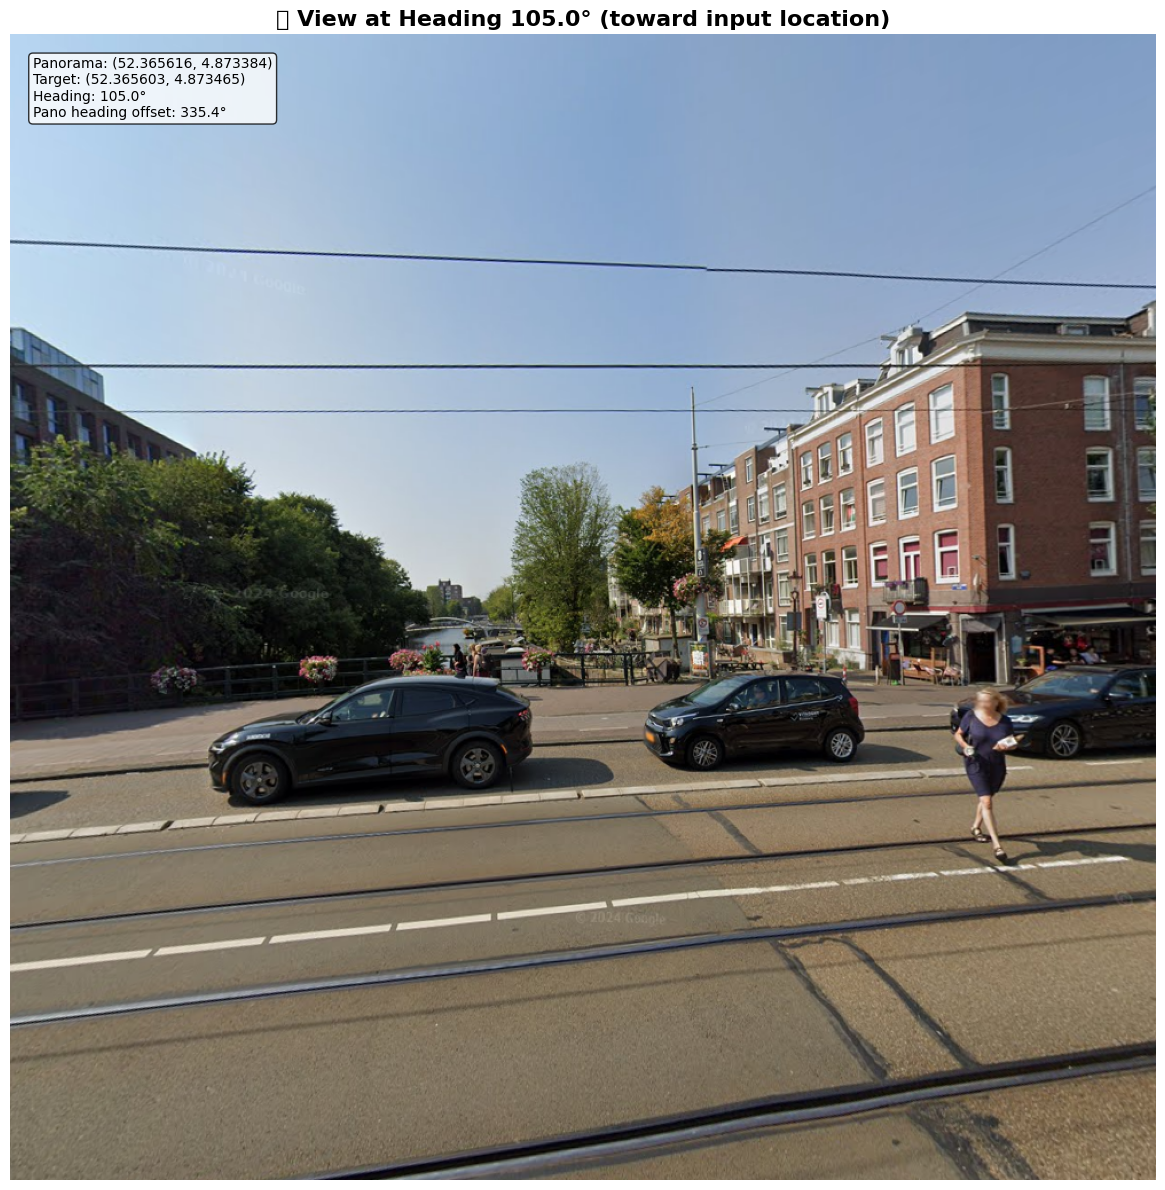


✅ This is the view from the panorama location looking toward your input coordinates!


In [ ]:
# =============================================================================
# Display the panorama at the calculated heading
# =============================================================================

if equirectangular and bearing_to_input is not None:
    # Get panorama heading in radians
    pano_heading_rad = metadata.get('heading') if metadata else None
    
    # Extract perspective view at the calculated bearing (accounting for pano heading)
    perspective_at_bearing = extract_perspective_view(
        equirectangular, 
        heading=bearing_to_input, 
        fov=90, 
        size=(1000, 1000),
        panorama_heading_rad=pano_heading_rad
    )
    
    # Display the perspective view
    fig, ax = plt.subplots(figsize=(12, 12))
    ax.imshow(perspective_at_bearing)
    ax.set_title(
        f'🎯 View at Heading {bearing_to_input:.1f}° (toward input location)',
        fontsize=16,
        fontweight='bold'
    )
    ax.axis('off')
    
    # Add bearing info text
    info_text = f"Panorama: ({metadata['lat']:.6f}, {metadata['lng']:.6f})\n"
    info_text += f"Target: ({INPUT_LAT:.6f}, {INPUT_LNG:.6f})\n"
    info_text += f"Heading: {bearing_to_input:.1f}°"
    
    ax.text(
        0.02, 0.98, info_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n✅ This is the view from the panorama location looking toward your input coordinates!")
else:
    print("Cannot display perspective view - no panorama or bearing available.")


In [ ]:
# =============================================================================
# Summary
# =============================================================================

if metadata:
    print("\n" + "="*60)
    print("📋 SUMMARY")
    print("="*60)
    print(f"\n📍 Input Location:")
    print(f"   Latitude:  {INPUT_LAT}")
    print(f"   Longitude: {INPUT_LNG}")
    
    print(f"\n📸 Panorama Found:")
    print(f"   Latitude:  {metadata['lat']}")
    print(f"   Longitude: {metadata['lng']}")
    print(f"   Pano ID:   {metadata['pano_id']}")
    print(f"   Date:      {metadata['date']}")
    
    if bearing_to_input is not None:
        print(f"\n🧭 Calculated Bearing:")
        print(f"   From panorama → input: {bearing_to_input:.1f}°")
        
        distance = haversine_distance(INPUT_LAT, INPUT_LNG, metadata['lat'], metadata['lng'])
        print(f"\n📏 Distance: {distance:.1f} meters")
    
    print("\n" + "="*60)
else:
    print("\n❌ No panorama found for the input location.")



📋 SUMMARY

📍 Input Location:
   Latitude:  52.36560281265296
   Longitude: 4.873465022986906

📸 Panorama Found:
   Latitude:  52.36561605971549
   Longitude: 4.873384291017278
   Pano ID:   X0E7lSfvQ683dOwoxqM8jQ
   Date:      2024-09
   Heading:   335.4° (panorama center direction)

🧭 Calculated Bearing:
   From panorama → input: 105.0°
   Adjusted local yaw:    440.4° (accounting for pano heading)

📏 Distance: 5.7 meters

